<font color="steelblue" size = 20px>***📘机器学习笔记***</font>

# <font color="limegreen">一.多特征线性回归模型</font>

In [1]:
#将要使用到的库
import copy
import math
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei", "SimSun"] #使得绘制图支持中文

## <font color="gold">1.自定义实验数据</font>

<img src="images\Data Correspondence.jpg" width="400" />

In [2]:
X_train = np.array([[2104, 5, 1, 45], [1416, 3, 2, 40], [852, 2, 1, 35]])
y_train = np.array([460, 232, 178])

## <font color="gold">2.数据归一化</font>

数据标准化原理：  
<img src="images\Normalization.jpg" width="350" />

在数据z-score归一化中：
使用numpy库中的  
mean方法<font color="orange">X_mean = np.mean(X_train, axis=0)</font>来计算特征值的数学期望，其中axis=0代表按列计算  
以及std方法<font color="orange">X_std = np.std(X_train, axis=0)</font>来计算特征值的标准差，其中axis=0同样代表按列计算  
最后对特征进行标准化<font color="orange">X_train_norm = (X_train - X_mean) / X_std</font>，此时的数据数学期望为0，标准差为1

数据归一化（标准化）的作用：  
标准化不会增加特征所包含的信息，但通常能改善梯度下降的收敛速度与稳定性。当特征尺度已经接近时，可以不做；当尺度差异明显时，通常值得做。预测新数据时，应使用训练集计算得到的均值和标准差。

In [3]:
print("数据归一化前：")
print(X_train)

print("数据归一化后：")
X_mean = np.mean(X_train, axis=0)
X_std = np.std(X_train, axis=0)
X_train_norm = (X_train - X_mean) / X_std
print(X_train_norm)

数据归一化前：
[[2104    5    1   45]
 [1416    3    2   40]
 [ 852    2    1   35]]
数据归一化后：
[[ 1.26311506  1.33630621 -0.70710678  1.22474487]
 [-0.08073519 -0.26726124  1.41421356  0.        ]
 [-1.18237987 -1.06904497 -0.70710678 -1.22474487]]


## <font color="gold">3.开始定义机器学习函数</font>

- 计算成本函数  
成本函数公式：  
<img src="images\CostFunction.png" width="300" />  
其中：  
<img src="images\Ffunction.png" width="250" />

In [4]:
def compute_cost(X, y, w, b):
    # X : 数据，m个样本，每个样本有n个特征
    # y : 目标值
    # w : 模型参数
    # b : 模型参数
    m = X.shape[0] #获取训练数据数量，此时m = 3
    cost = 0.0

    for i in range(m):
        f_wb_i = np.dot(X[i] , w) + b #使用numpy加速向量计算
        cost = cost + (f_wb_i - y[i])**2
    cost /= (2*m)

    return cost

- 计算梯度  
梯度计算公式（以线性回归为例）：  
<img src="images\DescentFunction.png" width="300" />  
其中：  
<img src="images\Ffunction.png" width="250" />

In [5]:
def compute_gradient(X, y, w, b):
    # X : 数据，m个样本，每个样本有n个特征
    # y : 目标值
    # w : 模型参数
    # b : 模型参数
    m,n = X.shape #获取训练数据的数据数量m，以及单个数据里有多少特征值n
    dj_dw = np.zeros((n,))
    dj_db = 0.

    for i in range (m):
        err = (np.dot(X[i], w) + b) - y[i]
        for j in range(n):
            dj_dw[j] = dj_dw[j] + err * X[i,j]
        dj_db += err
    dj_dw /= m
    dj_db /= m

    return dj_db,dj_dw

- 开始根据梯度更新每个参数  
<img src="images\UpdateParameter.png" width="400" />   
注意：  
1.其中的α为学习率，决定参数的改变幅度  
2.两个参数要同步更新

In [6]:
def gradient_descent(X, y, w_in, b_in, cost_function, gradient_function, alpha, num_iters):
    # X : 数据，m个样本，每个样本有n个特征
    # y : 目标值
    # w_in : 模型训练参数的初始值
    # b_in : 模型训练参数的初始值
    # cost_function : 成本计算函数
    # gradient_function : 梯度计算函数
    # alpha : α学习率
    # num_iters : 学习次数
    
    J_history = [] #用来记录参数更细的历史

    w = copy.deepcopy(w_in) #创建一个和w_in不相关但是数值相同的变量
    b = b_in

    for i in range(num_iters):
        dj_db,dj_dw = gradient_function(X, y, w, b)

        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        if i < 100000:
            J_history.append( cost_function(X, y, w, b))

        if i % math.ceil(num_iters / 10) == 0:
            print(f"Iteration {i:4d}: Cost {J_history[-1]:8.2f}")

    return w, b, J_history

## <font color="gold">4.开始进行机器学习</font>

定义机器学习参数  
开始学习前的最后准备

In [7]:
initial_w = np.zeros(4) #初始化线性回归w参数，全部为0
initial_b = 0 #初始化线性回归b参数为0

iterations =  1000 #学习的次数
alpha = 0.01 #学习率

开始机器学习

In [8]:
w_final, b_final, J_hist = gradient_descent(X_train_norm, y_train, initial_w, initial_b, compute_cost, compute_gradient, alpha, iterations)

Iteration    0: Cost 48254.77
Iteration  100: Cost  5582.45
Iteration  200: Cost   745.80
Iteration  300: Cost    99.90
Iteration  400: Cost    13.38
Iteration  500: Cost     1.79
Iteration  600: Cost     0.24
Iteration  700: Cost     0.03
Iteration  800: Cost     0.00
Iteration  900: Cost     0.00


绘制图，观察梯度下降过程中成本函数J的变化

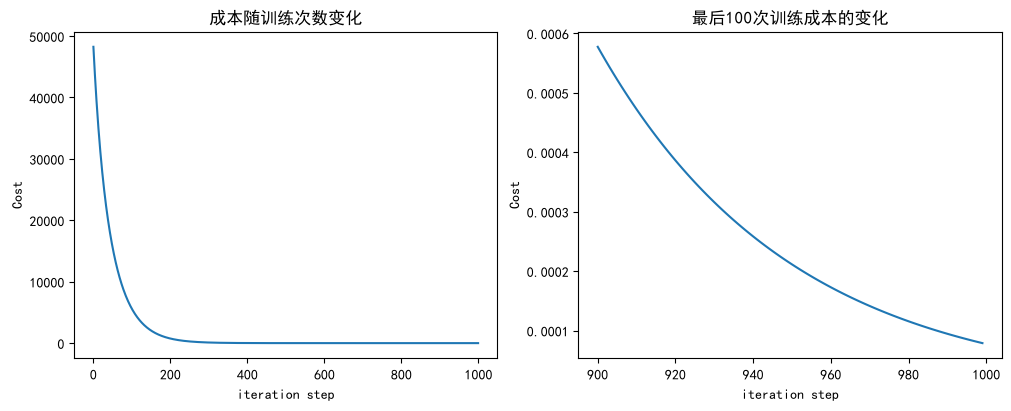

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, constrained_layout = True, figsize = (10 , 4))
#创建画布和子图，创建了一行二列的画图布局，其中fig是画布，ax1和ax2是左右两个子图，整个画布宽12，高4，布局为自动调整子图间距，防止标题、标签互相遮挡

ax1.plot(J_hist) #传入训练历史过程
ax2.plot(900 + np.arange(len(J_hist[900:])),J_hist[900:])

ax1.set_title("成本随训练次数变化");  ax2.set_title("最后100次训练成本的变化")
ax1.set_ylabel('Cost')             ;  ax2.set_ylabel('Cost') 
ax1.set_xlabel('iteration step')   ;  ax2.set_xlabel('iteration step') 

plt.show()

# <font color="limegreen">二.逻辑回归模型</font>

In [22]:
#将要使用到的库
import copy
import math
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["axes.unicode_minus"] = False

## <font color="gold">1.自定义实验数据</font>

In [11]:
X_train = np.array([[0.5, 1.5], [1, 1], [1.5, 0.5], [3, 0.5], [2, 2], [1, 2.5]])
y_train = np.array([0, 0, 0, 1, 1, 1])

## <font color="gold">2.开始定义机器学习函数</font>

- Sigmoid函数  
使用Sigmoid函数，将所有输入值映射到0和1之间，实现将输出转换为概率。

$$
g(z)=\frac{1}{1+e^{-z}}
$$

In [12]:
def sigmoid(z):
    g = 1/(1 + np.exp(-z))
    return g

- 成本函数


$$
J(w,b)=\frac{1}{m}\sum_{i=0}^{m-1}[loss(f_{w,b}(X^{(i)}),y^{(i)})]
$$
其中的损失函数为:  
$$
loss(f_{w,b}(X^{(i)}),y^{(i)})=-y^{(i)}\log(f_{w,b}(X^{(i)}))-(1-y^{(i)})\log(1-f_{w,b}(X^{(i)}))
$$
并且  
$ f_{w,b}(X^{(i)})=g(z^{(i)})$  
$ z^{(i)}=\mathbf{w}\mathbf{x}^{(i)}+b$

In [13]:
def compute_cost_logistic(X, y, w, b):
    m = X.shape[0]
    cost = 0.0
    for i in range(m):
        z_i = np.dot(X[i], w) + b
        f_wb_i = sigmoid(z_i)
        cost += -y[i] * np.log(f_wb_i) - (1 - y[i]) * np.log(1 - f_wb_i)
    cost /= m
    return cost

- 计算梯度

梯度推导过程：
$$
g'(z)=-\frac{1}{(1+e^{(-z)})^2}
$$  
化简得:$g'(z)=g(z)(1-g(z))$  
  
损失函数对$z^{(i)}$求导可得：
$$
\frac{\partial loss(g(z^{(i)}),y^{(i)})}{\partial z^{(i)}}=-y^{(i)}\frac{g(z^{(i)})(1-g(z^{(i)}))}{g(z^{(i)})}+(1-y^{(i)})\frac{g(z^{(i)})(1-g(z^{(i)}))}{1-g(z^{(i)})}
$$
化简可得：$\frac{\partial loss(g(z^{(i)}),y^{(i)})}{\partial z^{(i)}}=g(z^{(i)})-y^{(i)}=f_{w,b}(X^{(i)})-y^{(i)}$  
进一步对w和b分别求偏导可得到：
$$
\frac{\partial loss(f_{w,b}(X^{(i)}),y^{(i)})}{\partial w_j}=(f_{w,b}(X^{(i)})-y^{(i)})x^{(i)}_j
$$
$$
\frac{\partial loss(f_{w,b}(X^{(i)}),y^{(i)})}{\partial b}=(f_{w,b}(X^{(i)})-y^{(i)})*1
$$
  
最终可以得到所求的梯度：
$$
\frac{\partial J(w,b)}{\partial w_j}=\frac{1}{m}\sum_{i=0}^{m-1}(f_{w,b}(X^{(i)})-y^{(i)})x^{(i)}_j  \\
\frac{\partial J(w,b)}{\partial b}=\frac{1}{m}\sum_{i=0}^{m-1}(f_{w,b}(X^{(i)})-y^{(i)})
$$
最终可以观察到二元回归的梯度公式和线性回归的梯度公式一摸一样。

In [14]:
def compute_gradient_logistic(X, y, w, b):
    m, n = X.shape
    dj_dw = np.zeros((n,))
    dj_db = 0.0

    for i in range(m):
        f_wb_i = sigmoid(np.dot(X[i], w) + b)
        err_i = f_wb_i - y[i]
        for j in range(n):
            dj_dw[j] = dj_dw[j] + err_i * X[i, j]
        dj_db += err_i
    dj_dw /= m
    dj_db /= m
    return dj_dw, dj_db

- 梯度下降函数

$$
w_j = w_j-\alpha\frac{\partial J(w,b)}{\partial w_j}\\
b = b-\alpha\frac{\partial J(w,b)}{\partial b}
$$

In [18]:
def gradient_descent(X, y, w_in, b_in, alpha, num_iters): 
    J_history = []
    w = copy.deepcopy(w_in)
    b = copy.deepcopy(b_in)
    
    for i in range(num_iters):
        dj_dw, dj_db = compute_gradient_logistic(X, y, w, b) 
        w = w - alpha * dj_dw               
        b = b - alpha * dj_db               
      
        if i<100000:
            J_history.append( compute_cost_logistic(X, y, w, b) )

        if i% math.ceil(num_iters / 10) == 0:
            print(f"Iteration {i:4d}: Cost {J_history[-1]}   ")
        
    return w, b, J_history

## <font color="gold">3.开始进行机器学习</font>

定义机器学习参数

In [19]:
w_tmp = np.zeros_like(X_train[0])
b_tmp = 0.0
alpha = 0.1
iters = 10000

开始学习

In [20]:
w_out , b_out , J_history = gradient_descent(X_train, y_train, w_tmp, b_tmp, alpha, iters)
print(f"\nupdated parameters: w:{w_out}, b:{b_out}")

Iteration    0: Cost 0.684610468560574   
Iteration 1000: Cost 0.1590977666870456   
Iteration 2000: Cost 0.08460064176930081   
Iteration 3000: Cost 0.05705327279402531   
Iteration 4000: Cost 0.042907594216820076   
Iteration 5000: Cost 0.034338477298845684   
Iteration 6000: Cost 0.028603798022120097   
Iteration 7000: Cost 0.024501569608793   
Iteration 8000: Cost 0.02142370332569295   
Iteration 9000: Cost 0.019030137124109114   

updated parameters: w:[5.28123029 5.07815608], b:-14.222409982019837


绘制图像，展示训练后的决策边界

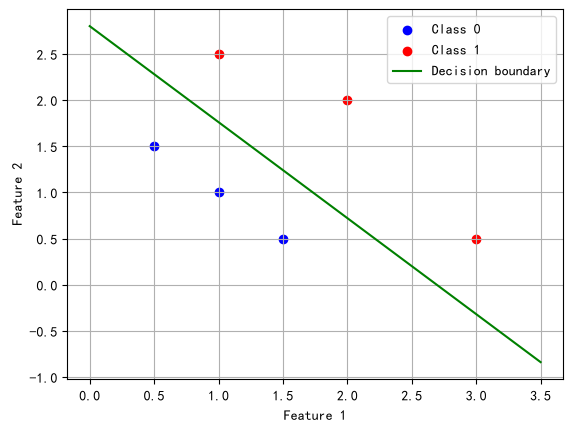

In [23]:
# 绘制两类训练样本
plt.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1],
            color="blue", label="Class 0")
plt.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1],
            color="red", label="Class 1")

# 根据训练后的参数计算决策边界
x1 = np.linspace(X_train[:, 0].min() - 0.5,
                 X_train[:, 0].max() + 0.5, 100)
x2 = -(w_out[0] * x1 + b_out) / w_out[1]

plt.plot(x1, x2, color="green", label="Decision boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid()
plt.show()

# <font color="limegreen">三.过拟合与正则化代价</font>

## <font color="gold">1.过拟合</font>

In [ ]:
%matplotlib widget
import matplotlib.pyplot as plt
from Orthers.Overfitting import overfit_example

plt.close("all")
ofit = overfit_example(False)  # False：分类；True：回归

## <font color="gold">2.正则化</font>

含正则化项的线性回归的代价函数：
$$
J(w,b)=\frac{1}{2m}\sum_{i=0}^{m-1}(f_{w,b}(x^{(i)})-y^{(i)})^2+\frac{\lambda}{2m}\sum_{j=0}^{n-1}w_j^2
$$
  
含正则化项的逻辑回归代价函数：
$$
J(w,b)=\frac{1}{m}\sum_{i=0}^{m-1}[-y^{(i)}\log(f_{w,b}(X^{(i)}))-(1-y^{(i)})\log(1-f_{w,b}(X^{(i)}))]+\frac{\lambda}{2m}\sum_{j=0}^{n-1}w_j^2
$$

正则化线性回归的代价函数

In [ ]:
def compute_cost_linear_reg(X, y, w, b, lambda_ = 1):
    m  = X.shape[0]
    n  = len(w)
    cost = 0.
    for i in range(m):
        f_wb_i = np.dot(X[i], w) + b
        cost = cost + (f_wb_i - y[i])**2
    cost = cost / (2 * m)

 #计算正则化项的值
    reg_cost = 0
    for j in range(n):
        reg_cost += (w[j]**2)
    reg_cost = (lambda_/(2*m)) * reg_cost
    
    total_cost = cost + reg_cost
    return total_cost

正则化逻辑回归的代价函数

In [ ]:
def compute_cost_logistic_reg(X, y, w, b, lambda_ = 1):
    m,n  = X.shape
    cost = 0.
    for i in range(m):
        z_i = np.dot(X[i], w) + b
        f_wb_i = sigmoid(z_i)
        cost +=  -y[i]*np.log(f_wb_i) - (1-y[i])*np.log(1-f_wb_i)
             
    cost = cost/m

    reg_cost = 0
    for j in range(n):
        reg_cost += (w[j]**2)
    reg_cost = (lambda_/(2*m)) * reg_cost
    
    total_cost = cost + reg_cost
    return total_cost                     

线性回归和逻辑回归的梯度计算几乎相同，只在计算$f(w,b)$时有所不同:  
$$
\frac{\partial J(w,b)}{\partial w_j}=\frac{1}{m}\sum_{i=0}^{m-1}(f_{w,b}(X^{(i)})-y^{(i)})x^{(i)}_j+\frac{\lambda}{m}w_j  \\
\frac{\partial J(w,b)}{\partial b}=\frac{1}{m}\sum_{i=0}^{m-1}(f_{w,b}(X^{(i)})-y^{(i)})
$$
线性回归:  
$f_{w,b}(x)=\mathbf{w}\cdot\mathbf{x}+b$  
逻辑回归:  
$f_{w,b}(x)=g(z)$  
  其中  
$z=\mathbf{w}\cdot\mathbf{x}+b$  
$g(z)=\frac{1}{1-e^{-z}}$


正则化线性回归的梯度函数

In [ ]:
def compute_gradient_linear_reg(X, y, w, b, lambda_): 
    m,n = X.shape
    dj_dw = np.zeros((n,))
    dj_db = 0.

    for i in range(m):                             
        err = (np.dot(X[i], w) + b) - y[i]                 
        for j in range(n):                         
            dj_dw[j] = dj_dw[j] + err * X[i, j]               
        dj_db = dj_db + err                        
    dj_dw = dj_dw / m                                
    dj_db = dj_db / m   
    
    for j in range(n):
        dj_dw[j] = dj_dw[j] + (lambda_/m) * w[j]

    return dj_db, dj_dw

正则化逻辑回归的梯度函数

In [ ]:
def compute_gradient_logistic_reg(X, y, w, b, lambda_): 
    m,n = X.shape
    dj_dw = np.zeros((n,))
    dj_db = 0.0

    for i in range(m):
        f_wb_i = sigmoid(np.dot(X[i],w) + b)
        err_i  = f_wb_i  - y[i]
        for j in range(n):
            dj_dw[j] = dj_dw[j] + err_i * X[i,j]
        dj_db = dj_db + err_i
    dj_dw = dj_dw/m
    dj_db = dj_db/m

    for j in range(n):
        dj_dw[j] = dj_dw[j] + (lambda_/m) * w[j]

    return dj_db, dj_dw  